# 03 Auswertung

Ziel: Teilfragen 1 und 2 beantworten: Wie entwickeln sich Umsatz, Gewinn und Marge über die Zeit, und welche Kategorien, Produkte und Filialtypen tragen am stärksten zum Gewinn bei? Grundlage sind die bereinigten Daten aus Notebook 02.

In [1]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("sqlite:///../data/processed/maven_toys.db")
connection = engine.connect()

sales_full = pd.read_sql("SELECT * FROM sales_full", connection, parse_dates=["Date"])
inventory_full = pd.read_sql("SELECT * FROM inventory_full", connection)

In [2]:
sales_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 829262 entries, 0 to 829261
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Sale_ID           829262 non-null  int64         
 1   Date              829262 non-null  datetime64[us]
 2   Units             829262 non-null  int64         
 3   Product_ID        829262 non-null  int64         
 4   Product_Name      829262 non-null  str           
 5   Product_Category  829262 non-null  str           
 6   Product_Cost      829262 non-null  float64       
 7   Product_Price     829262 non-null  float64       
 8   Store_ID          829262 non-null  int64         
 9   Store_Name        829262 non-null  str           
 10  Store_City        829262 non-null  str           
 11  Store_Location    829262 non-null  str           
 12  Revenue           829262 non-null  float64       
 13  Total_Cost        829262 non-null  float64       
 14  Profit         

## 1. Entwicklung über die Zeit
Umsatz, Gewinn und Marge werden pro Monat zusammengefasst. Die Daten reichen von Januar 2022 bis September 2023, also 21 Monate.

In [3]:
query_monthly = """
SELECT
    strftime('%Y-%m', Date) AS Month,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
GROUP BY Month
ORDER BY Month
"""

monthly = pd.read_sql(query_monthly, connection)
monthly

,Month,Revenue,Profit,Margin_Pct
0,2022-01,542554.91,167126.0,30.8
1,2022-02,541351.65,161861.0,29.9
2,2022-03,589485.19,173992.0,29.5
3,2022-04,681072.98,190099.0,27.9
4,2022-05,672369.90,186894.0,27.8
5,2022-06,661980.22,189815.0,28.7
6,2022-07,556034.23,176922.0,31.8
7,2022-08,489422.73,158931.0,32.5
8,2022-09,585844.04,166397.0,28.4
9,2022-10,623874.39,178799.0,28.7


### Umsatz und Gewinn im Zeitverlauf

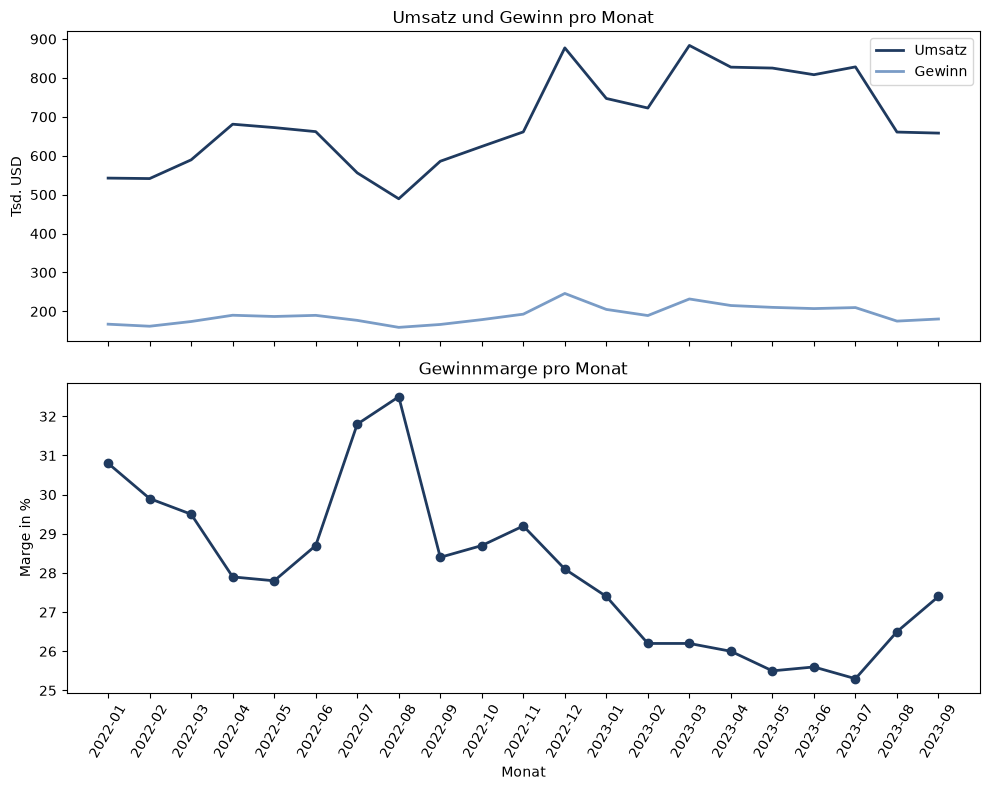

In [4]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(monthly["Month"], monthly["Revenue"] / 1000, label="Umsatz", color="#1f3a5f", linewidth=2)
ax1.plot(monthly["Month"], monthly["Profit"] / 1000, label="Gewinn", color="#7a9cc6", linewidth=2)
ax1.set_title("Umsatz und Gewinn pro Monat")
ax1.set_ylabel("Tsd. USD")
ax1.legend()

ax2.plot(monthly["Month"], monthly["Margin_Pct"], color="#1f3a5f", linewidth=2, marker="o")
ax2.set_title("Gewinnmarge pro Monat")
ax2.set_ylabel("Marge in %")
ax2.set_xlabel("Monat")
ax2.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

### Vergleich Januar bis September
Um die Jahre fair zu vergleichen, werden nur die Monate Januar bis September betrachtet, weil 2023 nur bis Ende September reicht.

In [5]:
query_yoy = """
SELECT
    strftime('%Y', Date) AS Year,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Year
ORDER BY Year
"""

yoy = pd.read_sql(query_yoy, connection)
yoy

,Year,Revenue,Profit,Margin_Pct
0,2022,5320115.85,1572037.0,29.5
1,2023,6962074.27,1824242.0,26.2


### Befunde Zeitverlauf
- Vergleich Januar bis September: Der Umsatz stieg 2023 gegenüber 2022 um rund 31 % (5,32 auf 6,96 Mio. USD), der Gewinn nur um rund 16 % (1,57 auf 1,82 Mio. USD).
- Die Marge sank von 29,5 % auf 26,2 %.
- Die Marge lag im August 2022 mit 32,5 % am höchsten, im Juli 2023 mit 25,3 % am niedrigsten und erholte sich bis September 2023 leicht auf 27,4 %.
- Saisonalität: Spitze im Dezember 2022 (rund 877.000 USD Umsatz), schwache Sommermonate 2022 (August rund 489.000 USD). Der höchste Monat insgesamt ist der März 2023 (rund 884.000 USD).
- Preise und Einkaufspreise sind pro Produkt konstant. Der Margenrückgang kann deshalb nur auf einer Verschiebung im Produktmix beruhen. Das wird in Teilfrage 2 geprüft.

## 2. Profitabilität nach Kategorie
Der Margenrückgang soll durch eine Verschiebung im Produktmix erklärt werden. Dazu werden Umsatz, Gewinn und Marge pro Produktkategorie für Januar bis September 2022 und 2023 verglichen.

In [6]:
query_category = """
SELECT
    Product_Category AS Category,
    strftime('%Y', Date) AS Year,
    ROUND(SUM(Revenue), 2) AS Revenue,
    ROUND(SUM(Profit), 2) AS Profit,
    ROUND(SUM(Profit) / SUM(Revenue) * 100, 1) AS Margin_Pct
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Category, Year
ORDER BY Category, Year
"""

category = pd.read_sql(query_category, connection)
category

,Category,Year,Revenue,Profit,Margin_Pct
0,Art & Crafts,2022,511146.27,144660.0,28.3
1,Art & Crafts,2023,1798723.38,480405.0,26.7
2,Electronics,2022,1117477.73,537290.0,48.1
3,Electronics,2023,806312.06,327030.0,40.6
4,Games,2022,829956.68,261807.0,31.5
5,Games,2023,998192.68,295612.0,29.6
6,Sports & Outdoors,2022,841765.18,184973.0,22.0
7,Sports & Outdoors,2023,1052931.70,250692.0,23.8
8,Toys,2022,2019769.99,443307.0,21.9
9,Toys,2023,2305914.45,470503.0,20.4


### Befunde Kategorien
- Electronics hat mit 48,1 % (2022) und 40,6 % (2023) die mit Abstand höchste Marge, verliert aber Umsatz (minus 28 %) und Gewinn (minus 39 %). Der Gewinnanteil sinkt von 34 % auf 18 %.
- Art & Crafts wächst von 0,51 auf 1,80 Mio. USD Umsatz (rund das 3,5-fache) und ist 2023 mit 26 % des Gewinns die größte Gewinnquelle.
- Toys ist mit 38 % bzw. 33 % des Umsatzes die größte Kategorie, hat aber mit rund 20 bis 22 % die niedrigste Marge.
- Sports & Outdoors ist die einzige Kategorie mit steigender Marge (22,0 auf 23,8 %).
- Der Rückgang der Gesamtmarge wird nur zu etwa einem Drittel durch die Verschiebung zwischen den Kategorien erklärt, zu etwa zwei Dritteln durch sinkende Margen innerhalb der Kategorien. Das wird auf Produktebene geprüft.

## 3. Profitabilität nach Produkt
Für jedes Produkt wird der Gewinn von Januar bis September 2022 und 2023 verglichen, um zu sehen, welche Produkte den Zuwachs und welche den Rückgang tragen.

In [7]:
query_product = """
SELECT
    Product_Name,
    Product_Category,
    ROUND(SUM(CASE WHEN strftime('%Y', Date) = '2022' THEN Profit ELSE 0 END), 0) AS Profit_2022,
    ROUND(SUM(CASE WHEN strftime('%Y', Date) = '2023' THEN Profit ELSE 0 END), 0) AS Profit_2023
FROM sales_full
WHERE strftime('%m', Date) <= '09'
GROUP BY Product_Name, Product_Category
"""

products_yoy = pd.read_sql(query_product, connection)
products_yoy["Profit_Change"] = products_yoy["Profit_2023"] - products_yoy["Profit_2022"]
products_yoy.sort_values("Profit_Change")

,Product_Name,Product_Category,Profit_2022,Profit_2023,Profit_Change
5,Colorbuds,Electronics,497096.0,233248.0,-263848.0
0,Action Figure,Toys,176976.0,125538.0,-51438.0
16,Kids Makeup Kit,Art & Crafts,77142.0,50622.0,-26520.0
6,Dart Gun,Sports & Outdoors,64508.0,40992.0,-23516.0
30,Splash Balls,Sports & Outdoors,31647.0,23208.0,-8439.0
19,Mini Basketball Hoop,Sports & Outdoors,20352.0,14560.0,-5792.0
26,PlayDoh Toolkit,Art & Crafts,13070.0,7662.0,-5408.0
31,Supersoaker Water Gun,Sports & Outdoors,10581.0,7839.0,-2742.0
33,Toy Robot,Electronics,26730.0,24230.0,-2500.0
9,Dinosaur Figures,Toys,50484.0,48112.0,-2372.0


### Befunde Produkte
- Colorbuds (Electronics) ist der größte Einzelfaktor: Der Gewinn sinkt von 497.000 auf 233.000 USD (minus 53 %). Das Produkt machte 2022 rund 32 % des gesamten Gewinns aus, 2023 nur noch rund 13 %.
- Der Zuwachs bei Art & Crafts wird vor allem von Barrel O' Slime, Magic Sand, Etch A Sketch und Playfoam getragen. Etch A Sketch, Playfoam und Foam Disk Launcher hatten 2022 keinen Gewinn und wurden vermutlich erst später eingeführt.
- Weitere Gewinnrückgänge: Action Figure (minus 51.000), Kids Makeup Kit (minus 26.500), Dart Gun (minus 23.500).
- Der Margenrückgang ergibt sich damit aus dem Einbruch eines margenstarken Produkts und dem Wachstum margenschwächerer Produkte.

### Erster und letzter Verkaufstag je Produkt
Um zu prüfen, ob Produkte neu ins Sortiment kamen, wird pro Produkt der erste und der letzte Verkaufstag bestimmt.

In [8]:
query_dates = """
SELECT
    Product_Name,
    Product_Category,
    SUBSTR(MIN(Date), 1, 10) AS First_Sale,
    SUBSTR(MAX(Date), 1, 10) AS Last_Sale
FROM sales_full
GROUP BY Product_Name, Product_Category
ORDER BY First_Sale DESC
"""

product_dates = pd.read_sql(query_dates, connection)
product_dates

,Product_Name,Product_Category,First_Sale,Last_Sale
0,Playfoam,Art & Crafts,2023-08-17,2023-09-30
1,Foam Disk Launcher,Sports & Outdoors,2023-03-07,2023-09-30
2,Etch A Sketch,Art & Crafts,2022-11-11,2023-09-30
3,Mr. Potatohead,Toys,2022-08-01,2023-09-30
4,Magic Sand,Art & Crafts,2022-07-29,2023-09-30
5,Gamer Headphones,Electronics,2022-07-14,2023-09-30
6,Plush Pony,Toys,2022-06-14,2023-09-30
7,PlayDoh Playset,Art & Crafts,2022-05-17,2023-09-29
8,Jenga,Games,2022-05-16,2023-09-30
9,Supersoaker Water Gun,Sports & Outdoors,2022-03-19,2023-09-30


### Neue Produkte und Bestandsprodukte
Produkte, die erst nach dem 01.01.2022 erstmals verkauft wurden, gelten als neu. Es wird verglichen, wie viel Gewinn neue Produkte und Bestandsprodukte im Vergleich Januar bis September 2022 und 2023 beigetragen haben.

In [9]:
new_products = product_dates.loc[product_dates["First_Sale"] > "2022-01-01", "Product_Name"]

products_yoy["Is_New"] = products_yoy["Product_Name"].isin(new_products)

products_yoy.groupby("Is_New")[["Profit_2022", "Profit_2023", "Profit_Change"]].sum()

,Profit_2022,Profit_2023,Profit_Change
Is_New,,,
False,1463078.0,1362907.0,-100171.0
True,108959.0,461335.0,352376.0


### Befunde Sortiment
- 11 von 35 Produkten wurden erst nach dem 01.01.2022 eingeführt, die übrigen 24 sind seit Beginn dabei. Kein Produkt wurde bis Ende September 2023 aus dem Sortiment genommen.
- Im Vergleich Januar bis September stieg der Gewinn der neuen Produkte um rund 352.000 USD, während der Gewinn der Bestandsprodukte um rund 100.000 USD sank. Das Wachstum stammt damit vollständig aus der Sortimentserweiterung.
- Der Rückgang im Bestand geht vor allem auf Colorbuds zurück (minus 264.000 USD).
- Einschränkung: Weil das Sortiment 2023 größer ist, ist der Vergleich der beiden Zeiträume nicht vollständig gleichartig.